# График, которому можно верить

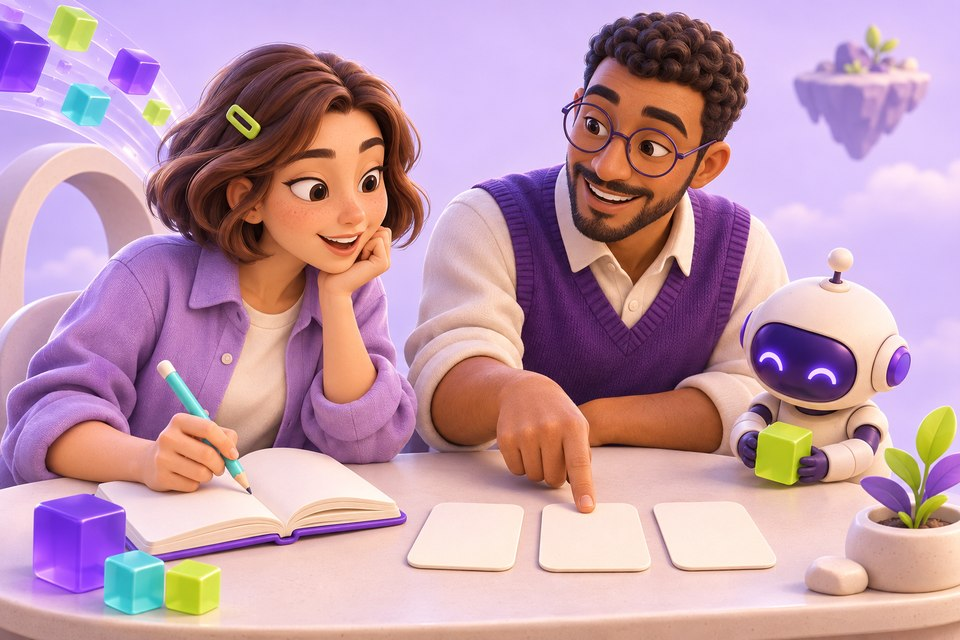

**Подпишем формулы правильно и проверим данные под линиями.**

**Твой результат:** Построить линейную, квадратную и кубическую кривые без скрытых лишних серий.

**Что разбираем:** Короткий практический маршрут Matplotlib; оставшиеся примеры оригинала доступны в архиве.

**Данные:** Точки, рассчитанные по формулам x, x² и x³.

**Перед началом:**

- Python 3 и указанные библиотеки
- Запускай шаги сверху вниз

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. [Сначала проверь числа](#step-1)
2. [Покажи кривые на одних осях](#step-2)
3. [Разнеси квадрат и куб по панелям](#step-3)

[Твой эксперимент](#your-experiment)

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **numpy, matplotlib**.

In [1]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams.update({
    'figure.figsize': (7, 3.5), 'figure.dpi': 100,
    'figure.facecolor': '#fffdf8', 'axes.facecolor': '#fffdf8',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelcolor': '#302c3f',
    'text.color': '#302c3f', 'savefig.bbox': 'tight',
})
import numpy as np
import matplotlib.pyplot as plt


<a id="step-1"></a>

## 1. Сначала проверь числа

Создадим ровно три зависимости. Числа с дробной частью в Python пишутся через точку; запятая разделяет аргументы.

In [2]:
x = np.linspace(0, 2, 101)
curves = {'y = x': x, 'y = x²': x**2, 'y = x³': x**3}
assert all(values.shape == x.shape for values in curves.values())
assert curves['y = x²'][-1] == 4
assert curves['y = x³'][-1] == 8
print('При x=2:')
for name, values in curves.items():
    print(name, '→', values[-1])


При x=2:
y = x → 2.0
y = x² → 4.0
y = x³ → 8.0


**Что проверить:** При x=2 получаются 2,4,8 — подписи можно проверить до рисунка.

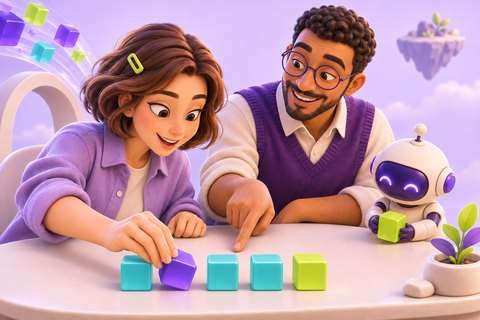

> **Мира:** Почему x**0,15 не означает степень 0.15?

> **Данил:** Запятая завершает аргумент. Нужна десятичная точка; иначе plot получает дополнительные данные.

> **Пикс:** Проверяй крайние значения формулы, а не только красивую линию.

<a id="step-2"></a>

## 2. Покажи кривые на одних осях

Одна фигура помогает сравнивать рост. Подписи строятся из того же словаря, что и данные.

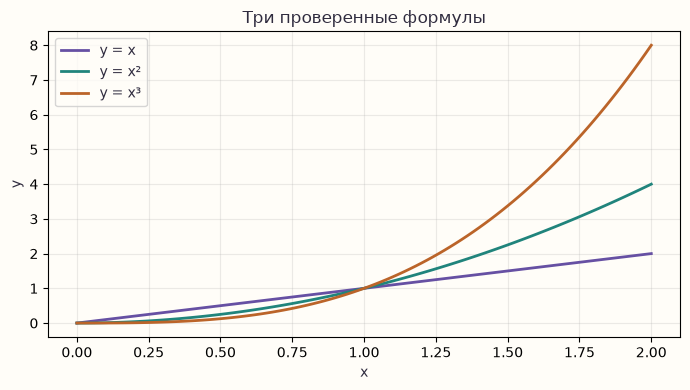

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#6650a3', '#20847c', '#bb6429']
for (name, values), color in zip(curves.items(), colors):
    ax.plot(x, values, label=name, color=color, linewidth=2)
ax.set(xlabel='x', ylabel='y', title='Три проверенные формулы')
ax.grid(alpha=0.25)
ax.legend()
assert len(ax.lines) == 3
assert [line.get_label() for line in ax.lines] == list(curves)
plt.tight_layout()
plt.show()


**Что проверить:** Ровно три линии; каждая легенда соответствует формуле.

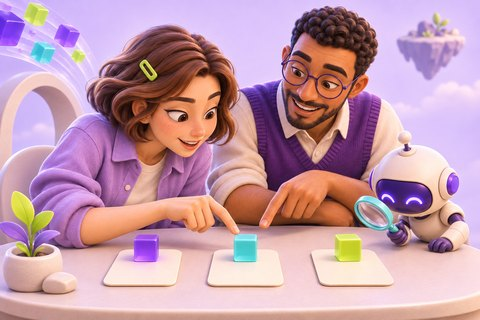

> **Мира:** Кубическая линия выглядит самой высокой — этого достаточно?

> **Данил:** Нет: неверная формула тоже может выглядеть убедительно. Мы проверили числа и привязку подписей.

> **Пикс:** Число ax.lines должно быть 3, без случайной четвёртой серии.

<a id="step-3"></a>

## 3. Разнеси квадрат и куб по панелям

Отдельные панели полезны, когда одна кривая перекрывает другую. У каждой будет собственное название и обе подписи осей.

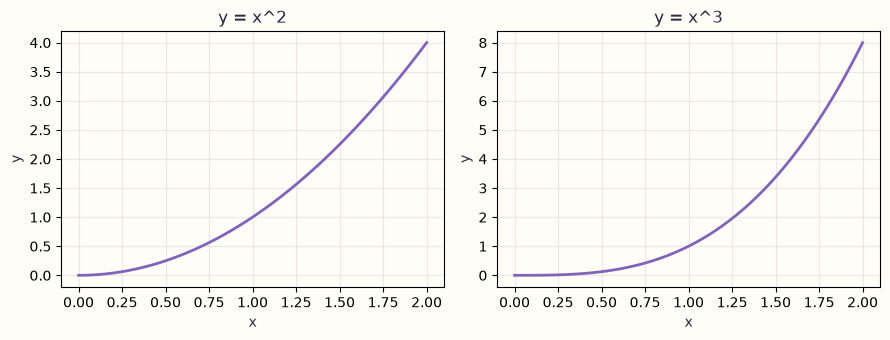

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, power in zip(axes, [2, 3]):
    values = x**power
    ax.plot(x, values, color='#8164ba', linewidth=2)
    ax.set(title=f'y = x^{power}', xlabel='x', ylabel='y')
    ax.grid(alpha=0.25)
    assert np.array_equal(ax.lines[0].get_ydata(), values)
assert axes[0].get_title() == 'y = x^2'
assert axes[1].get_title() == 'y = x^3'
plt.tight_layout()
plt.show()


**Что проверить:** Две панели с верными названиями; подпись куба больше не говорит «квадрат».

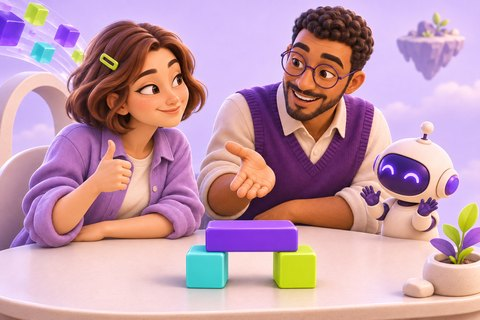

> **Мира:** Лучше держать подпись отдельно от формулы?

> **Данил:** Лучше получать их из одного power. Так смена степени не оставит старое название.

> **Пикс:** Данные линии проверены через get_ydata, а не только по заголовку.

<a id="your-experiment"></a>

## Попробуй сам

Сравни степени 2 и 4.

**Где изменить:** Список [2,3] в третьем шаге и ожидаемый заголовок второй панели.

**Как проверить:** При x=2 четвёртая степень равна 16; название показывает 4.

## Что теперь умеешь

- Точный график начинается с правильных чисел.
- Формула, легенда и подписи должны описывать одно и то же.

## Границы этого примера

- Это учебные функции, не наблюдения и не доказательство связи реальных величин.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/Matplotlib/matplotlib.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/matplotlib.ipynb>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 3 (от 0).** Запятая превращает дробную степень в дополнительные аргументы plot. → Явные x**2 и x**3 в именованном словаре.

Проверка: Ровно 3 линии и значения 4/8 приx=2.

Фрагмент исходника: <code>ax.plot(x,x**0,15,label=&quot;quadratic&quot;)</code>

---

**Ошибка · исходная ячейка 8 (от 0).** Заголовок заявляет x², хотя y2 рассчитан как x³. → Формула и название генерируются из power.

Проверка: Заголовок второй панели y=x^3; её ydata равны x**3.

Фрагмент исходника: <code>y2=[i**3 for i in x]; title содержитy2=x^2</code>

</details>